# ✈️ Flight Fare Prediction — End-to-End Machine Learning Project

**A beginner-friendly, step-by-step regression project**

In this notebook we will build a model that predicts flight ticket prices based on
features like airline, source, destination, duration, number of stops, and date of journey.

We will go through the **complete data science workflow**:

1. Load & explore the raw dataset
2. basic checks and Clean the data
3. Engineer new features
4. handling the outliers and missing values.
5. Encode categorical variables
6. Split into train/test sets
7. Train **multiple** regression models
8. Tune hyperparameters with **GridSearchCV** anf **RandomizedsearchCV**
9. Evaluate models with **K-Fold Cross-Validation** and **strafied k-fold cross-validation**
10. After running all the models.
11. Compare all models and choose the good accuracy model and pick the best one.
12. Save the final model as a `.pkl` file
13. Reload the saved model and make a prediction, to prove it works
14. build a UI using the **streamlit** for better experience and to predict the data using website **(optional)**.

> 💡 Every step includes comments explaining **why** we do it, not just how — this notebook
> is written for someone new to data science.

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_excel("Flight_Fare.xlsx")
data

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648


In [3]:
data.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [4]:
data.tail()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648
10682,Air India,9/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,10:55,19:15,8h 20m,2 stops,No info,11753


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [6]:
data.dtypes

Airline            object
Date_of_Journey    object
Source             object
Destination        object
Route              object
Dep_Time           object
Arrival_Time       object
Duration           object
Total_Stops        object
Additional_Info    object
Price               int64
dtype: object

In [7]:
data.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [8]:
data.describe(include = "object").T

,count,unique,top,freq
Airline,10683,12,Jet Airways,3849
Date_of_Journey,10683,44,18/05/2019,504
Source,10683,5,Delhi,4537
Destination,10683,6,Cochin,4537
Route,10682,128,DEL → BOM → COK,2376
Dep_Time,10683,222,18:55,233
Arrival_Time,10683,1343,19:00,423
Duration,10683,368,2h 50m,550
Total_Stops,10682,5,1 stop,5625
Additional_Info,10683,10,No info,8345


In [9]:
data.nunique()

Airline              12
Date_of_Journey      44
Source                5
Destination           6
Route               128
Dep_Time            222
Arrival_Time       1343
Duration            368
Total_Stops           5
Additional_Info      10
Price              1870
dtype: int64

In [10]:
data.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price'],
      dtype='object')

In [11]:
data.shape

(10683, 11)

In [12]:
cat = data.select_dtypes(include="object").columns
cat

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info'],
      dtype='object')

In [13]:
num = data.select_dtypes(exclude="object").columns
num

Index(['Price'], dtype='object')

In [14]:
# check unique values
for x in cat:
  print(x , '-->' , data[x].unique())

Airline --> ['IndiGo' 'Air India' 'Jet Airways' 'SpiceJet' 'Multiple carriers' 'GoAir'
 'Vistara' 'Air Asia' 'Vistara Premium economy' 'Jet Airways Business'
 'Multiple carriers Premium economy' 'Trujet']
Date_of_Journey --> ['24/03/2019' '1/05/2019' '9/06/2019' '12/05/2019' '01/03/2019'
 '24/06/2019' '12/03/2019' '27/05/2019' '1/06/2019' '18/04/2019'
 '9/05/2019' '24/04/2019' '3/03/2019' '15/04/2019' '12/06/2019'
 '6/03/2019' '21/03/2019' '3/04/2019' '6/05/2019' '15/05/2019'
 '18/06/2019' '15/06/2019' '6/04/2019' '18/05/2019' '27/06/2019'
 '21/05/2019' '06/03/2019' '3/06/2019' '15/03/2019' '3/05/2019'
 '9/03/2019' '6/06/2019' '24/05/2019' '09/03/2019' '1/04/2019'
 '21/04/2019' '21/06/2019' '27/03/2019' '18/03/2019' '12/04/2019'
 '9/04/2019' '1/03/2019' '03/03/2019' '27/04/2019']
Source --> ['Banglore' 'Kolkata' 'Delhi' 'Chennai' 'Mumbai']
Destination --> ['New Delhi' 'Banglore' 'Cochin' 'Kolkata' 'Delhi' 'Hyderabad']
Route --> ['BLR → DEL' 'CCU → IXR → BBI → BLR' 'DEL → LKO → BOM → CO

In [15]:
data.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [16]:
data.duplicated().sum()

np.int64(220)

In [17]:
data.drop_duplicates(inplace=True)

In [18]:
data.duplicated().sum()

np.int64(0)

In [19]:
data.shape

(10463, 11)

In [20]:
data.dropna(inplace= True)

In [21]:
data.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

In [22]:
data.count()

Airline            10462
Date_of_Journey    10462
Source             10462
Destination        10462
Route              10462
Dep_Time           10462
Arrival_Time       10462
Duration           10462
Total_Stops        10462
Additional_Info    10462
Price              10462
dtype: int64

In [23]:
data["Additional_Info"].value_counts()

Additional_Info
No info                         8182
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

In [24]:
data["Airline"].value_counts()

Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1694
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

In [25]:
data["Date_of_Journey"].value_counts()

Date_of_Journey
6/06/2019     490
18/05/2019    486
9/06/2019     485
12/06/2019    483
21/05/2019    482
9/05/2019     466
21/03/2019    412
15/05/2019    402
27/05/2019    369
27/06/2019    339
24/06/2019    330
1/06/2019     330
3/06/2019     326
15/06/2019    314
24/03/2019    314
6/03/2019     302
27/03/2019    290
24/05/2019    286
6/05/2019     281
1/05/2019     274
12/05/2019    259
1/04/2019     256
3/03/2019     217
9/03/2019     199
15/03/2019    162
18/03/2019    156
01/03/2019    151
12/03/2019    141
9/04/2019     125
3/04/2019     110
21/06/2019    109
18/06/2019    105
6/04/2019     100
09/03/2019    100
06/03/2019     95
27/04/2019     94
03/03/2019     92
24/04/2019     92
3/05/2019      90
15/04/2019     89
21/04/2019     82
18/04/2019     67
12/04/2019     63
1/03/2019      47
Name: count, dtype: int64

In [26]:
data["Date_of_Journey"] = pd.to_datetime(
    data["Date_of_Journey"],
    dayfirst=True
)

In [27]:
data.dtypes

Airline                    object
Date_of_Journey    datetime64[ns]
Source                     object
Destination                object
Route                      object
Dep_Time                   object
Arrival_Time               object
Duration                   object
Total_Stops                object
Additional_Info            object
Price                       int64
dtype: object

In [28]:
data["Journey_Day"] = data["Date_of_Journey"].dt.day
data["Journey_Month"] = data["Date_of_Journey"].dt.month
data["Journey_Year"] = data["Date_of_Journey"].dt.year

In [29]:
data.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_Day', 'Journey_Month',
       'Journey_Year'],
      dtype='object')

In [30]:
data.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,2019
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,2019
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,2019
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,2019
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,2019


In [31]:
data["Dep_Hour"] = data["Dep_Time"].str.split(":").str[0].astype(int)

In [32]:
data.groupby("Dep_Hour")["Price"].mean()

Dep_Hour
0      7615.075000
1      4354.621622
2      8419.974227
3     10474.625000
4      7266.520710
5      9480.309278
6      8252.195556
7      8485.902665
8     10073.923631
9      9559.092551
10     8870.728653
11     9296.739206
12     9251.573034
13     8998.725061
14     9816.409901
15     7687.410658
16    10330.783080
17     8710.355588
18    10043.981859
19     8344.700368
20     9683.838213
21     8450.296524
22     7765.975871
23     8487.338346
Name: Price, dtype: float64

In [33]:
def get_time_period(hour):
    if hour < 6:
        return "Early Morning"
    elif hour < 12:
        return "Morning"
    elif hour < 18:
        return "Afternoon"
    else:
        return "Evening"

data["Dep_Period"] = data["Dep_Hour"].apply(get_time_period)

In [34]:
data.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Period
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,2019,22,Evening
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,2019,5,Early Morning
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,2019,9,Morning
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,2019,18,Evening
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,2019,16,Afternoon


In [35]:
data["Dep_Time"].value_counts()

Dep_Time
18:55    233
17:00    227
07:05    202
07:10    201
10:00    196
        ... 
04:50      1
12:45      1
12:05      1
21:40      1
03:00      1
Name: count, Length: 222, dtype: int64

In [36]:
def duration_to_minutes(duration):
    hours = 0
    minutes = 0
    
    if "h" in duration:
        hours = int(duration.split("h")[0])
        
    if "m" in duration:
        minutes = int(duration.split("h")[-1].replace("m", "").strip())
        
    return hours * 60 + minutes

data["Duration_Minutes"] = data["Duration"].apply(duration_to_minutes)

In [37]:
data[["Duration", "Duration_Minutes", "Price"]].head()

,Duration,Duration_Minutes,Price
0,2h 50m,170,3897
1,7h 25m,445,7662
2,19h,1140,13882
3,5h 25m,325,6218
4,4h 45m,285,13302


In [38]:
data.groupby("Duration_Minutes")["Price"].mean()

Duration_Minutes
5       17327.000000
75       3944.333333
80       3286.377049
85       5011.162963
90       3721.484456
            ...     
2480    13990.000000
2525    11664.000000
2565    12819.000000
2820    20064.000000
2860    20694.000000
Name: Price, Length: 368, dtype: float64

In [39]:
def dep_time_to_minutes(time):
    hours, minutes = map(int, time.split(":"))
    return hours * 60 + minutes

data["Dep_Time_Minutes"] = data["Dep_Time"].apply(dep_time_to_minutes)

In [40]:
data.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Period,Duration_Minutes,Dep_Time_Minutes
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,2019,22,Evening,170,1340
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,2019,5,Early Morning,445,350
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,2019,9,Morning,1140,565
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,2019,18,Evening,325,1085
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,2019,16,Afternoon,285,1010


In [41]:
# data.drop("Dep_Minutes", axis=1, inplace=True)

KeyError: "['Dep_Minutes'] not found in axis"

In [42]:
def arrival_time_to_minutes(time):
    time = str(time).strip()
    time = time.split()[0]
    hours, minutes = map(int, time.split(":"))
    return hours * 60 + minutes

data["Arrival_Time_Minutes"] = data["Arrival_Time"].apply(
    arrival_time_to_minutes
)

In [43]:
data.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Period,Duration_Minutes,Dep_Time_Minutes,Arrival_Time_Minutes
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,2019,22,Evening,170,1340,70
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,2019,5,Early Morning,445,350,795
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,2019,9,Morning,1140,565,265
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,2019,18,Evening,325,1085,1410
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,2019,16,Afternoon,285,1010,1295


In [44]:
def split_arrival_time(value):
    value = str(value).strip()
    parts = value.split()

    time = parts[0]

    if len(parts) == 3:
        date = parts[1]
        month = parts[2]
    else:
        date = None
        month = None

    return pd.Series([date, month, time])


data[["Arrival_Date", "Arrival_Month", "Arrival_Time"]] = (
    data["Arrival_Time"].apply(split_arrival_time)
)

In [45]:
data.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,...,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Period,Duration_Minutes,Dep_Time_Minutes,Arrival_Time_Minutes,Arrival_Date,Arrival_Month
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10,2h 50m,non-stop,No info,...,24,3,2019,22,Evening,170,1340,70,22,Mar
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,...,1,5,2019,5,Early Morning,445,350,795,None,None
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25,19h,2 stops,No info,...,9,6,2019,9,Morning,1140,565,265,10,Jun
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,...,12,5,2019,18,Evening,325,1085,1410,None,None
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,...,1,3,2019,16,Afternoon,285,1010,1295,None,None


In [46]:
data["Route"].value_counts()


Route
DEL → BOM → COK                      2376
BLR → DEL                            1536
CCU → BOM → BLR                       979
CCU → BLR                             724
BOM → HYD                             621
                                     ... 
BOM → VNS → DEL → HYD                   1
BLR → HBX → BOM → NAG → DEL             1
BLR → BOM → IXC → DEL                   1
BLR → CCU → BBI → HYD → VGA → DEL       1
BOM → BBI → HYD                         1
Name: count, Length: 128, dtype: int64

In [47]:
data.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_Day', 'Journey_Month',
       'Journey_Year', 'Dep_Hour', 'Dep_Period', 'Duration_Minutes',
       'Dep_Time_Minutes', 'Arrival_Time_Minutes', 'Arrival_Date',
       'Arrival_Month'],
      dtype='object')

In [48]:
data.nunique()

Airline                   12
Date_of_Journey           40
Source                     5
Destination                6
Route                    128
Dep_Time                 222
Arrival_Time             223
Duration                 368
Total_Stops                5
Additional_Info           10
Price                   1870
Journey_Day               10
Journey_Month              4
Journey_Year               1
Dep_Hour                  24
Dep_Period                 4
Duration_Minutes         368
Dep_Time_Minutes         222
Arrival_Time_Minutes     223
Arrival_Date              19
Arrival_Month              4
dtype: int64

In [ ]:
plt.figure(figsize=(20,10))
sns.scatterplot(data,x='Price',y = "Airline", hue = "Airline")
plt.show()

In [ ]:
plt.figure(figsize=(30,8))
sns.histplot(data,x='Airline',kde=True,color='red',bins=20)
plt.show()

In [ ]:
plt.figure(figsize=(20,5))
sns.countplot(data,x='Airline')
plt.show()

In [ ]:
plt.figure(figsize=(20,3))
sns.histplot(data,x='Date_of_Journey',kde =True, bins = 15,color= "green")
plt.show()

In [ ]:
plt.figure(figsize=(20,3))
sns.kdeplot(data,x='Price')
plt.show()

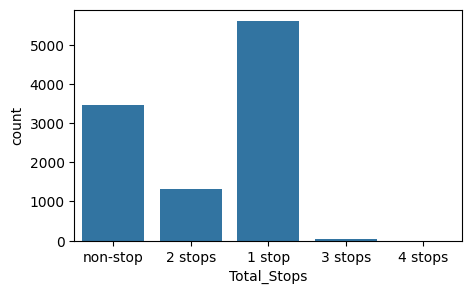

In [51]:
plt.figure(figsize=(5,3))
sns.countplot(data,x='Total_Stops')
plt.show()

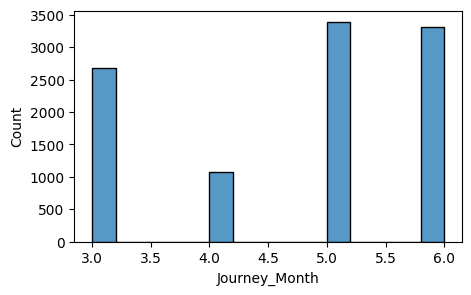

In [52]:
plt.figure(figsize=(5,3))
sns.histplot(data,x='Journey_Month')
plt.show()

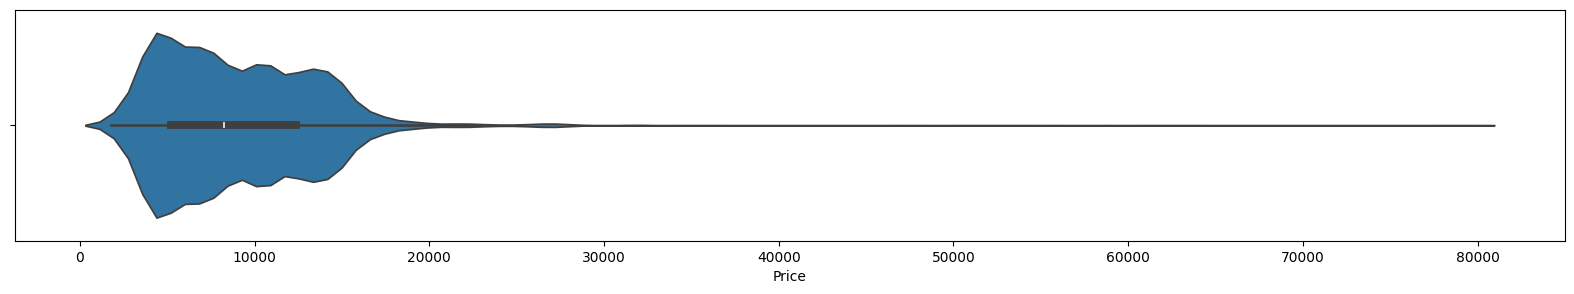

In [53]:
plt.figure(figsize=(20,3))
sns.violinplot(data,x='Price')
plt.show()

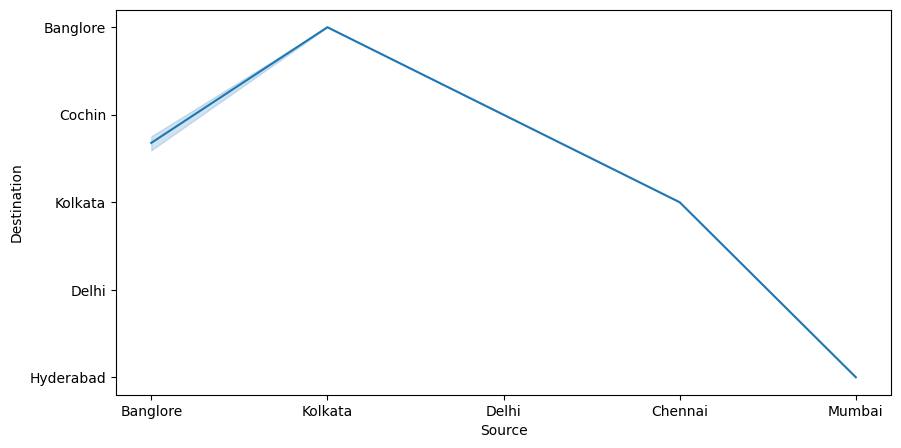

In [54]:
plt.figure(figsize=(10,5))
sns.lineplot(data,x="Source", y="Destination")
plt.show()

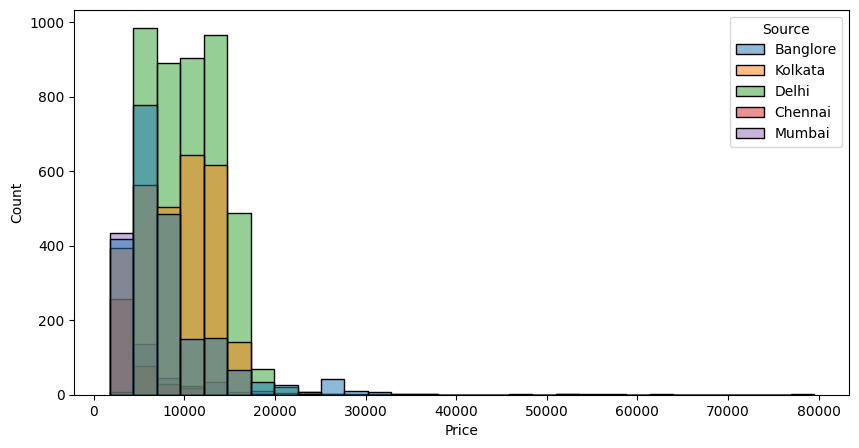

In [55]:
plt.figure(figsize=(10,5))
sns.histplot(data,x="Price",hue = "Source",bins=30)
plt.show()

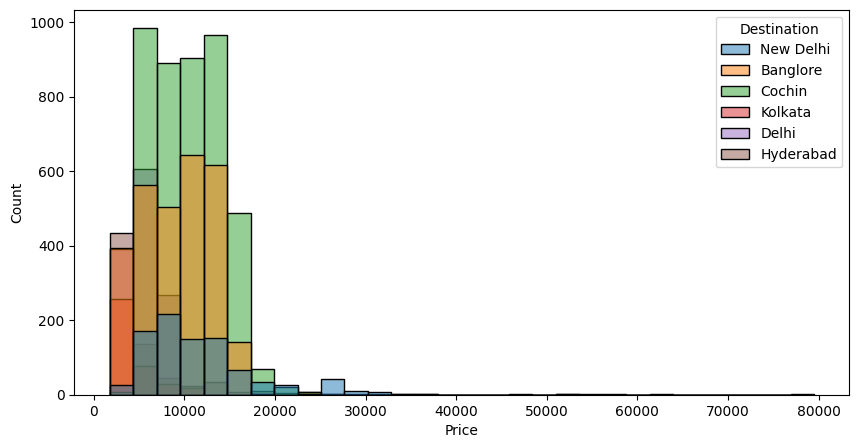

In [56]:
plt.figure(figsize=(10,5))
sns.histplot(data,x="Price",hue = "Destination",bins=30)
plt.show()

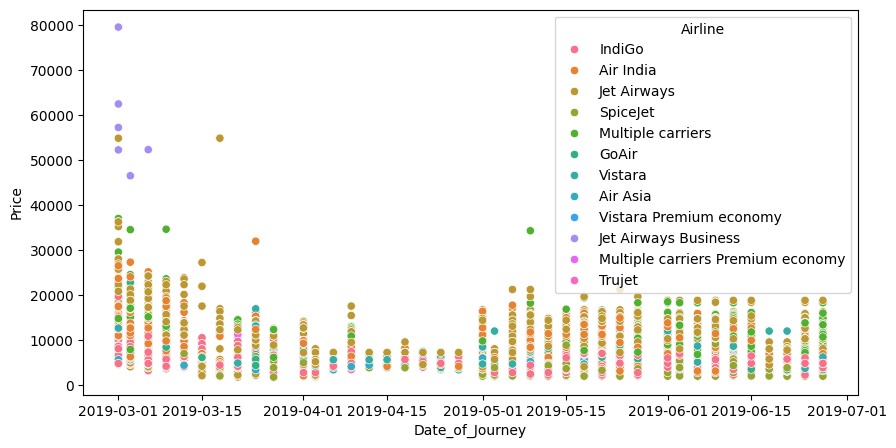

In [57]:
plt.figure(figsize=(10,5))
sns.scatterplot(data,x="Date_of_Journey",y="Price",hue="Airline")
plt.show()

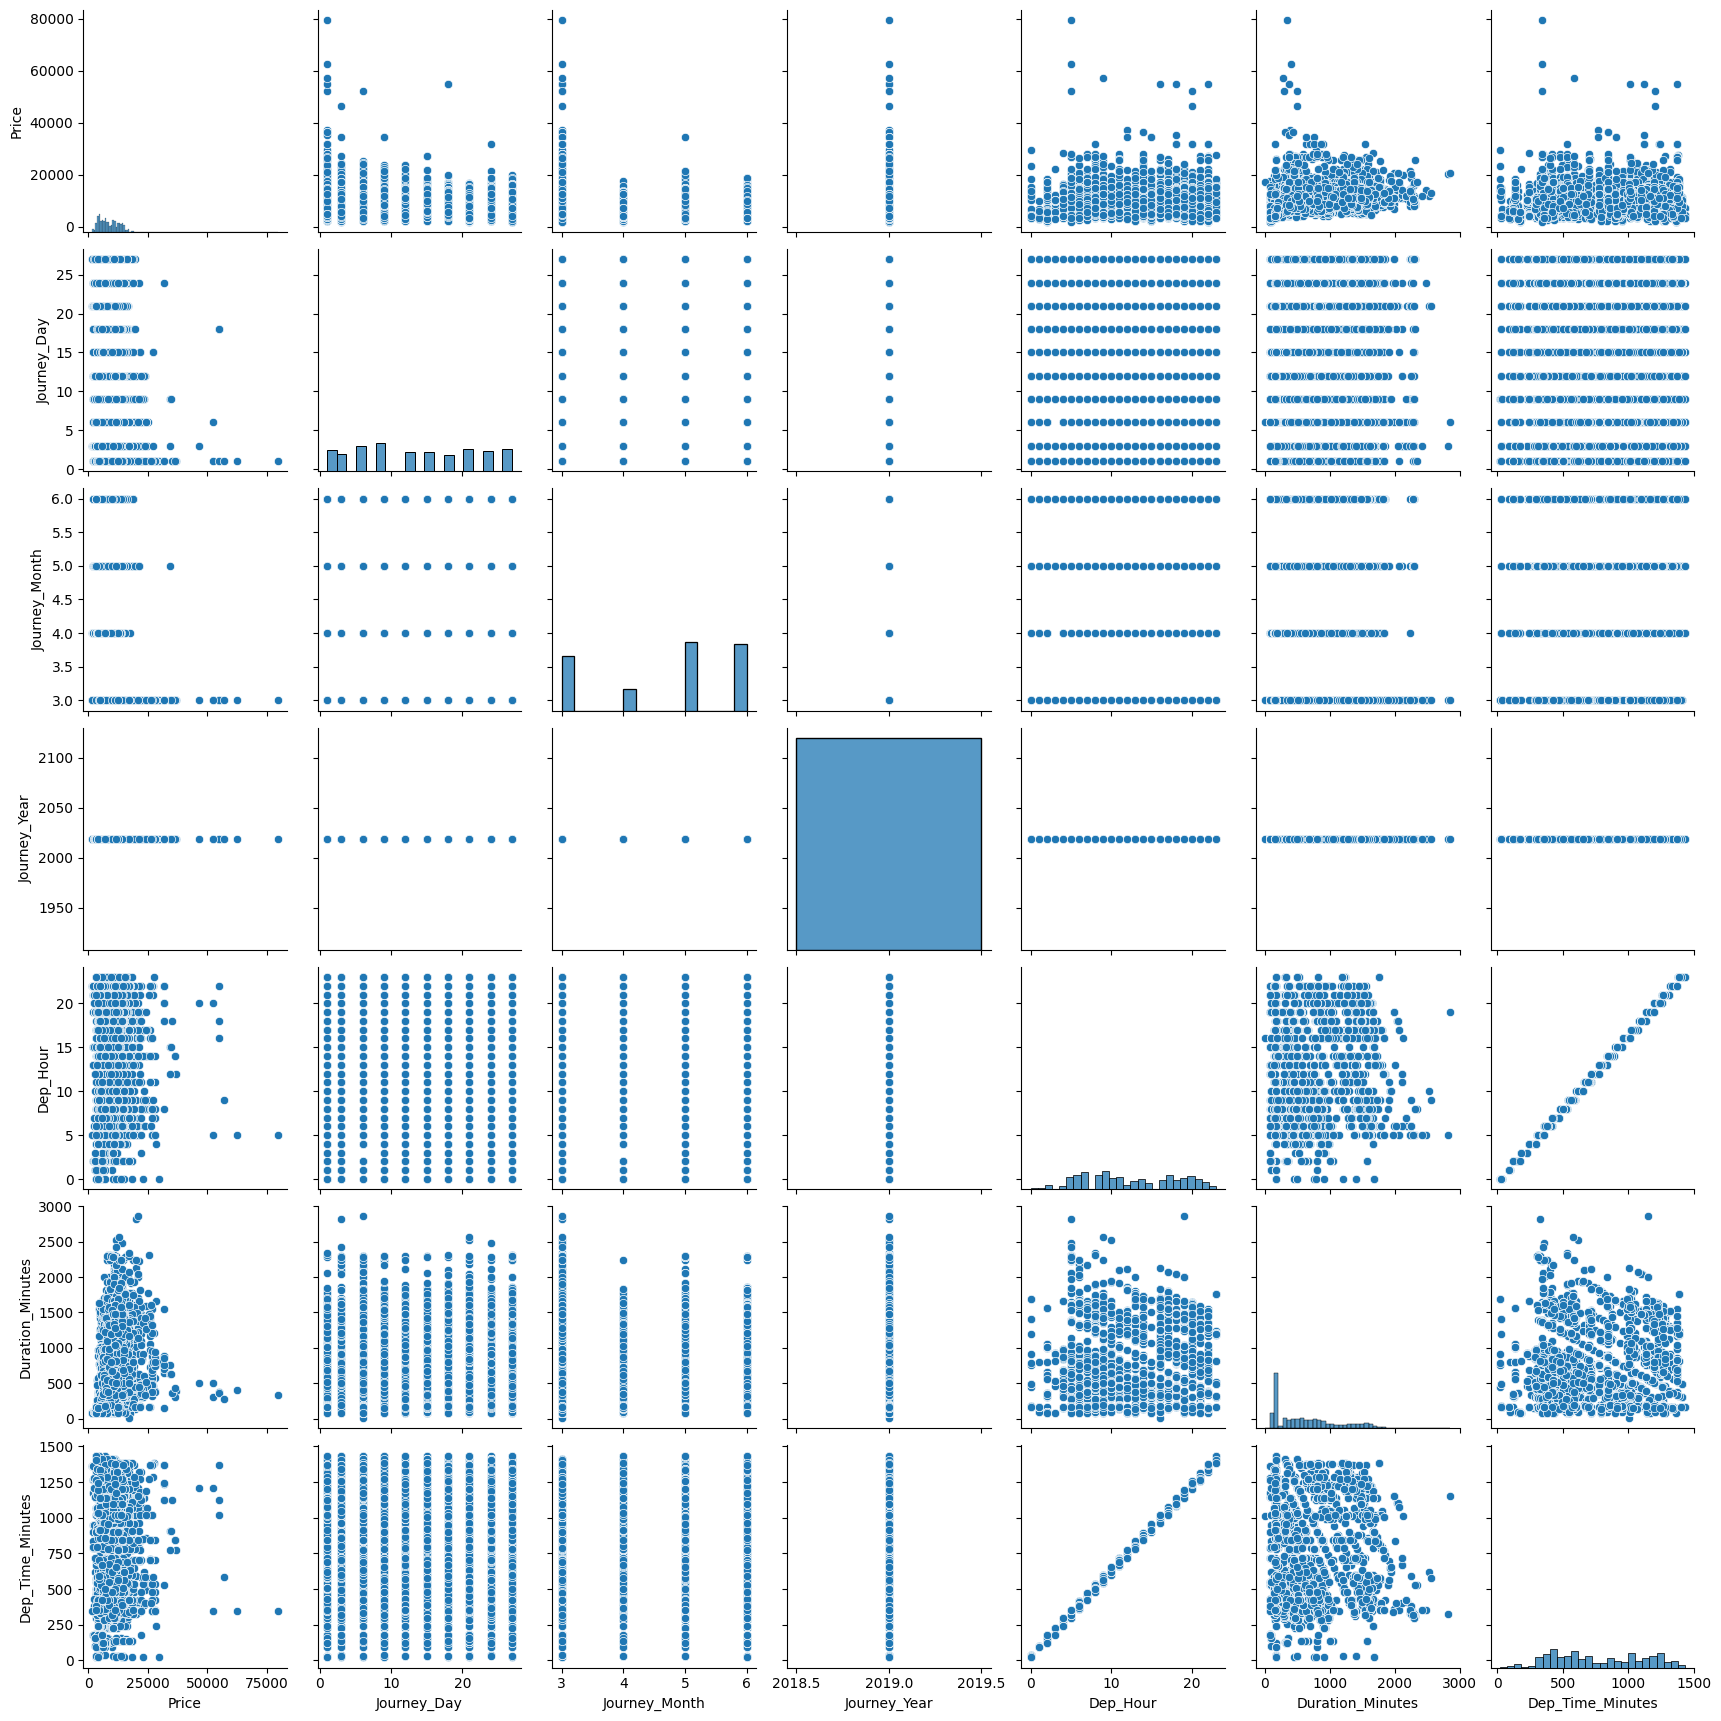

In [58]:
sns.pairplot(data)

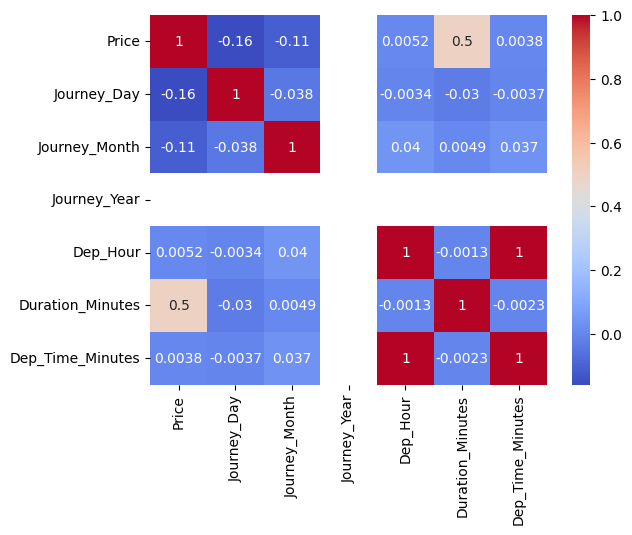

In [59]:
sns.heatmap(data.corr(numeric_only=True),annot=True,cmap="coolwarm")
plt.show()

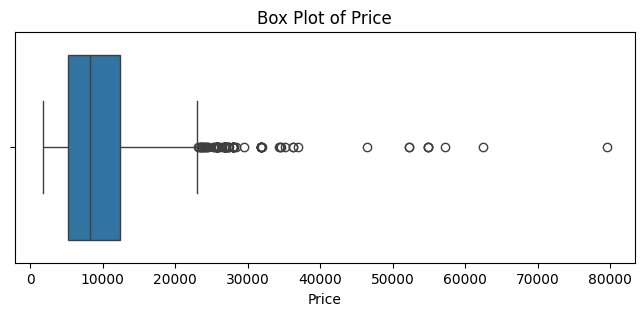

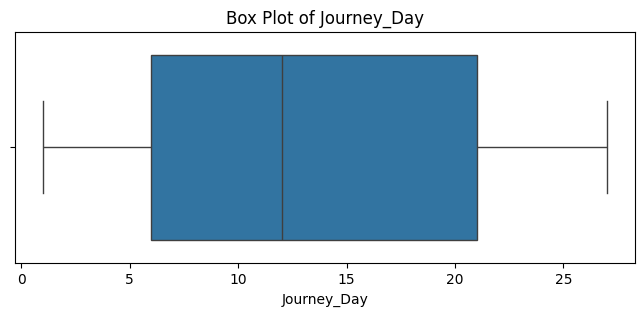

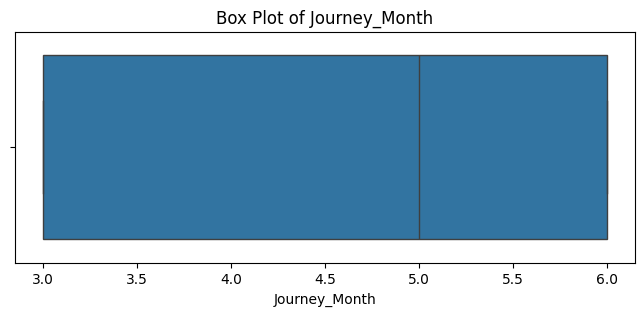

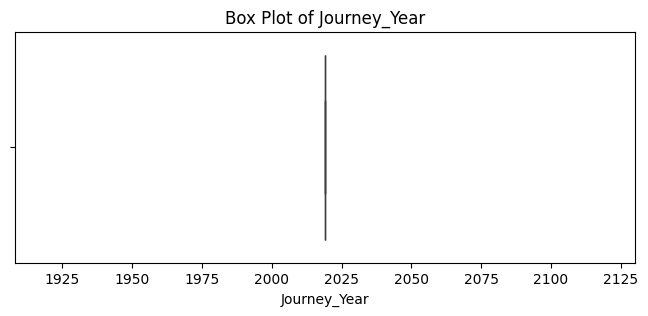

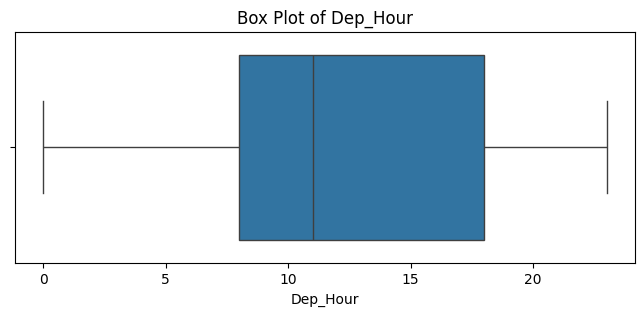

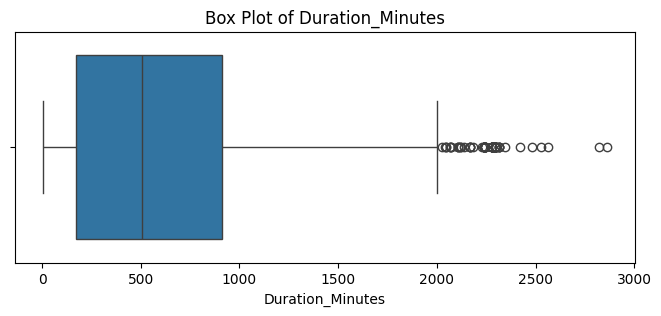

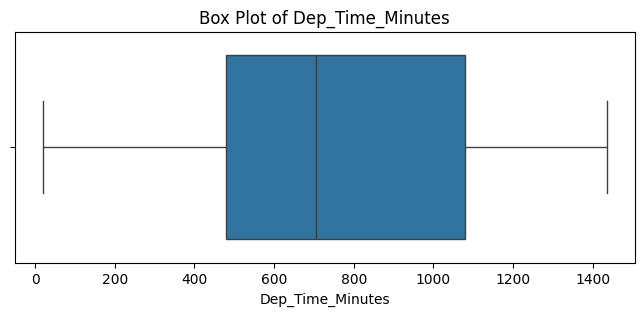

In [60]:
numeric_cols = data.select_dtypes(include="number").columns

for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=data[col])
    plt.title(f"Box Plot of {col}")
    plt.show()

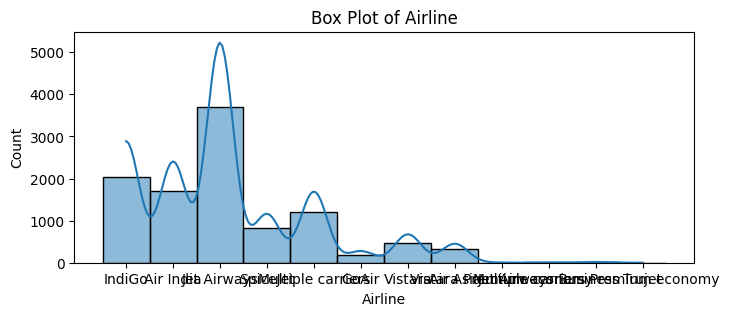

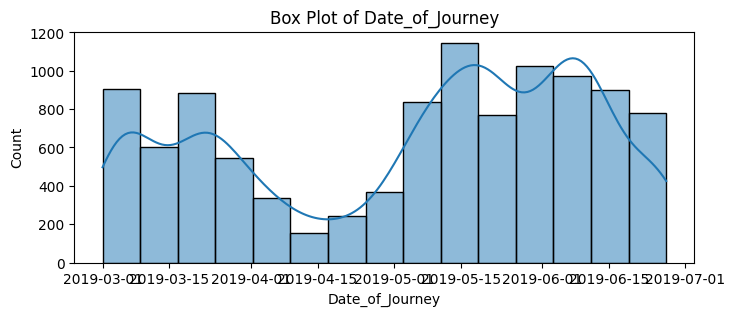

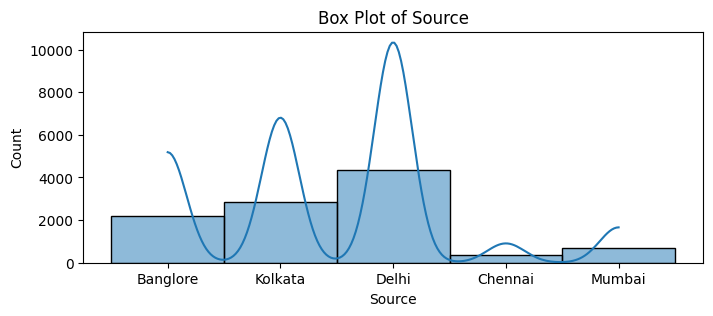

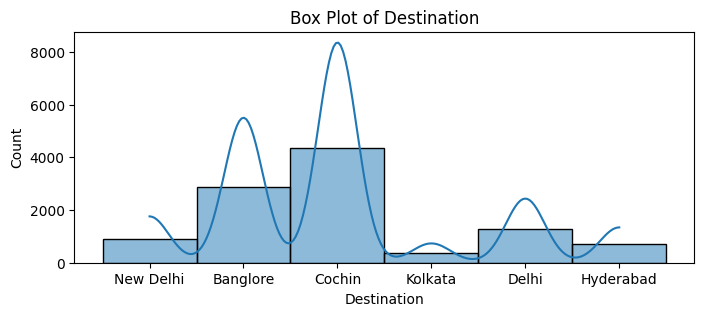

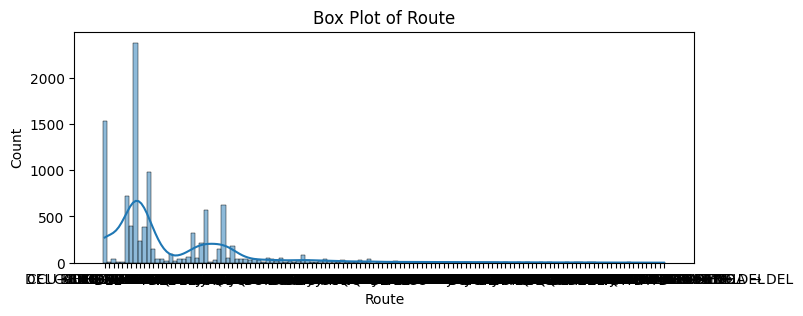

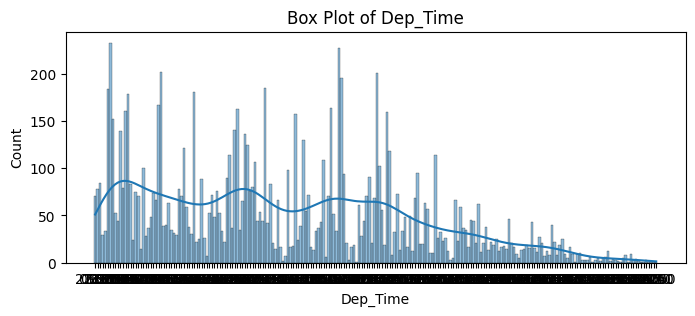

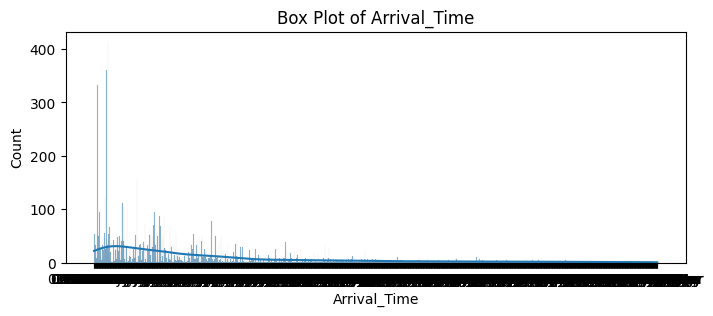

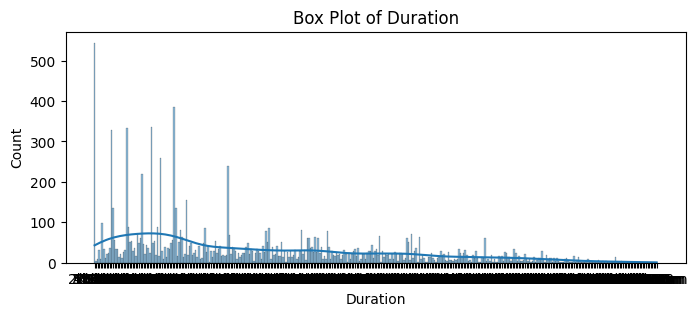

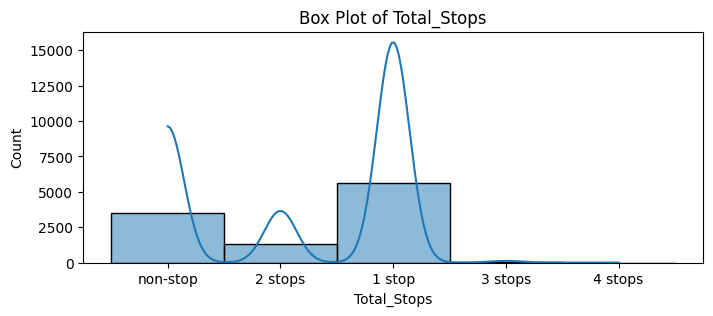

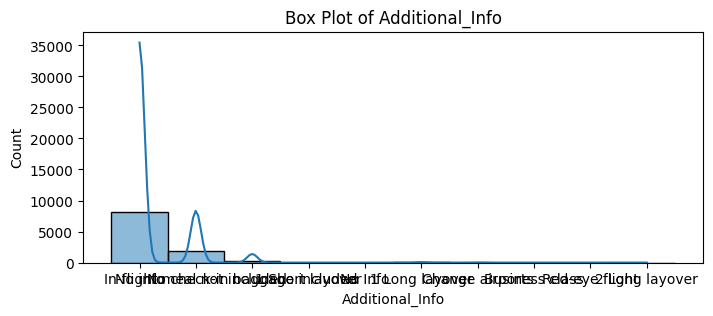

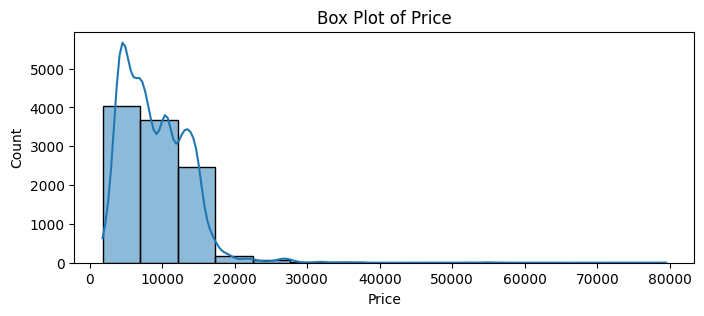

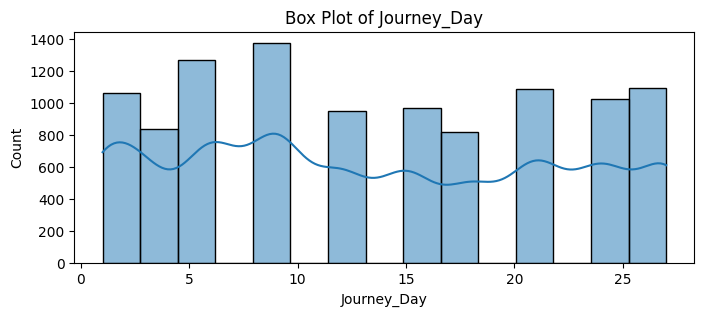

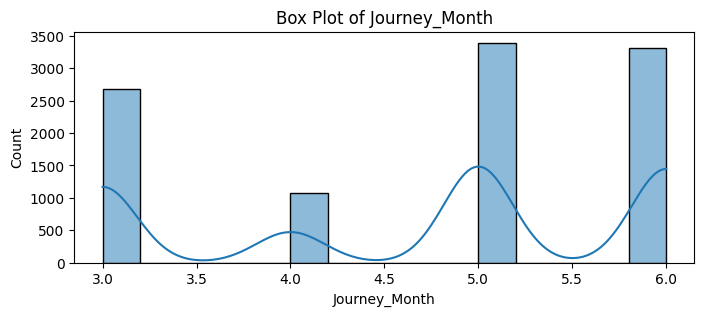

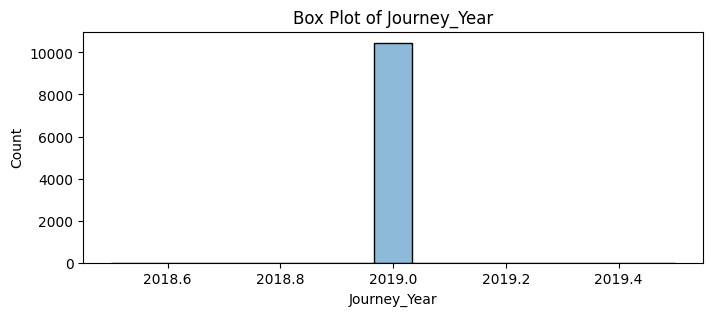

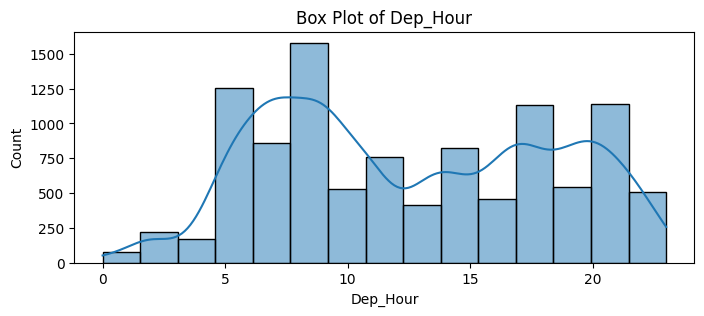

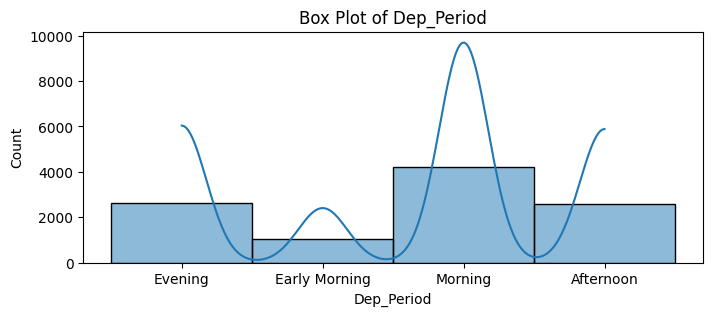

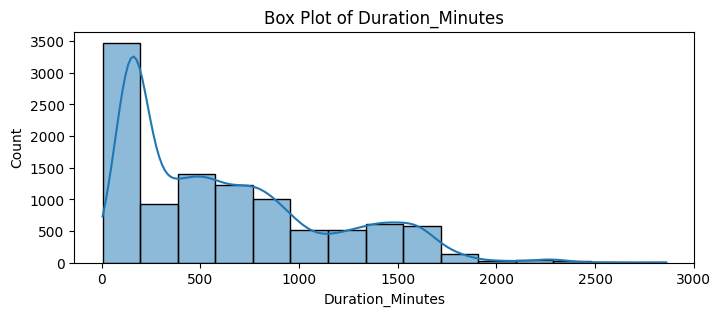

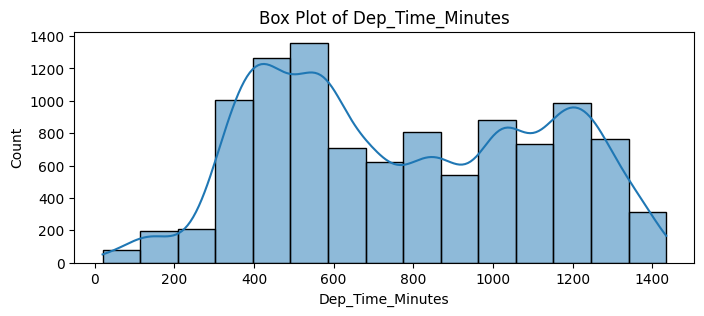

In [61]:
#numeric_cols = data.select_dtypes(include="number").columns

for col in data:
    plt.figure(figsize=(8, 3))
    sns.histplot(x=data[col],kde = True, bins = 15)
    plt.title(f"Box Plot of {col}")
    plt.show()

In [49]:
data['Price'].skew()

np.float64(1.8574899082173875)

In [50]:
# find outliers in charges
Q1 = data.loc[:,'Price'].quantile(0.25)
Q3 = data.loc[:,'Price'].quantile(0.75)
IQR = Q3-Q1
lower_limit = Q1 - 1.5*IQR
upper_limit = Q3 + 1.5* IQR

In [51]:
data[data.loc[:,'Price']<lower_limit]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,...,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Period,Duration_Minutes,Dep_Time_Minutes,Arrival_Time_Minutes,Arrival_Date,Arrival_Month


In [52]:
data[data.loc[:,'Price']> upper_limit]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,...,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Period,Duration_Minutes,Dep_Time_Minutes,Arrival_Time_Minutes,Arrival_Date,Arrival_Month
123,Air India,2019-03-01,Delhi,Cochin,DEL → BOM → COK,23:00,19:15,20h 15m,1 stop,No info,...,1,3,2019,23,Evening,1215,1380,1155,02,Mar
396,Multiple carriers,2019-03-01,Delhi,Cochin,DEL → BOM → COK,12:50,19:15,6h 25m,1 stop,No info,...,1,3,2019,12,Afternoon,385,770,1155,None,None
486,Jet Airways,2019-03-01,Banglore,New Delhi,BLR → BOM → DEL,08:55,15:15,6h 20m,1 stop,No info,...,1,3,2019,8,Morning,380,535,915,None,None
510,Jet Airways,2019-03-01,Banglore,New Delhi,BLR → BOM → DEL,07:00,12:25,5h 25m,1 stop,No info,...,1,3,2019,7,Morning,325,420,745,None,None
597,Air India,2019-03-06,Mumbai,Hyderabad,BOM → JDH → DEL → HYD,09:40,15:15,29h 35m,2 stops,No info,...,6,3,2019,9,Morning,1775,580,915,07,Mar
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10353,Jet Airways,2019-03-06,Mumbai,Hyderabad,BOM → BDQ → DEL → HYD,19:50,16:50,21h,2 stops,No info,...,6,3,2019,19,Evening,1260,1190,1010,07,Mar
10364,Jet Airways Business,2019-03-01,Banglore,New Delhi,BLR → MAA → DEL,09:45,14:25,4h 40m,1 stop,Business class,...,1,3,2019,9,Morning,280,585,865,None,None
10383,Jet Airways,2019-03-01,Banglore,New Delhi,BLR → BOM → DEL,07:00,05:05,22h 5m,1 stop,No info,...,1,3,2019,7,Morning,1325,420,305,02,Mar
10439,Jet Airways,2019-03-01,Banglore,New Delhi,BLR → BOM → DEL,18:40,09:00,14h 20m,1 stop,No info,...,1,3,2019,18,Evening,860,1120,540,02,Mar


In [53]:
data[(data.loc[:,'Price']<lower_limit) | (data.loc[:,'Price']> upper_limit)]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,...,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Period,Duration_Minutes,Dep_Time_Minutes,Arrival_Time_Minutes,Arrival_Date,Arrival_Month
123,Air India,2019-03-01,Delhi,Cochin,DEL → BOM → COK,23:00,19:15,20h 15m,1 stop,No info,...,1,3,2019,23,Evening,1215,1380,1155,02,Mar
396,Multiple carriers,2019-03-01,Delhi,Cochin,DEL → BOM → COK,12:50,19:15,6h 25m,1 stop,No info,...,1,3,2019,12,Afternoon,385,770,1155,None,None
486,Jet Airways,2019-03-01,Banglore,New Delhi,BLR → BOM → DEL,08:55,15:15,6h 20m,1 stop,No info,...,1,3,2019,8,Morning,380,535,915,None,None
510,Jet Airways,2019-03-01,Banglore,New Delhi,BLR → BOM → DEL,07:00,12:25,5h 25m,1 stop,No info,...,1,3,2019,7,Morning,325,420,745,None,None
597,Air India,2019-03-06,Mumbai,Hyderabad,BOM → JDH → DEL → HYD,09:40,15:15,29h 35m,2 stops,No info,...,6,3,2019,9,Morning,1775,580,915,07,Mar
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10353,Jet Airways,2019-03-06,Mumbai,Hyderabad,BOM → BDQ → DEL → HYD,19:50,16:50,21h,2 stops,No info,...,6,3,2019,19,Evening,1260,1190,1010,07,Mar
10364,Jet Airways Business,2019-03-01,Banglore,New Delhi,BLR → MAA → DEL,09:45,14:25,4h 40m,1 stop,Business class,...,1,3,2019,9,Morning,280,585,865,None,None
10383,Jet Airways,2019-03-01,Banglore,New Delhi,BLR → BOM → DEL,07:00,05:05,22h 5m,1 stop,No info,...,1,3,2019,7,Morning,1325,420,305,02,Mar
10439,Jet Airways,2019-03-01,Banglore,New Delhi,BLR → BOM → DEL,18:40,09:00,14h 20m,1 stop,No info,...,1,3,2019,18,Evening,860,1120,540,02,Mar


In [54]:
len(data[(data.loc[:,'Price']<lower_limit) | (data.loc[:,'Price']> upper_limit)])/len(data)*100

0.8984897725100364

In [55]:

data.loc[(data.loc[:,'Price']<lower_limit) | (data.loc[:,'Price']>upper_limit),'Price']=data.loc[:,'Price'].mean()

C:\Users\Girish M\AppData\Local\Temp\ipykernel_21048\2912877294.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '9026.790288663735' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  data.loc[(data.loc[:,'Price']<lower_limit) | (data.loc[:,'Price']>upper_limit),'Price']=data.loc[:,'Price'].mean()


In [56]:
len(data[(data.loc[:,'Price']<lower_limit) | (data.loc[:,'Price']> upper_limit)])/len(data)*100

0.0

In [57]:
data['Price'].skew()

np.float64(0.4469616270526865)

In [58]:
data.iloc[:,:10]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10,2h 50m,non-stop,No info
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25,19h,2 stops,No info
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info
...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,2019-04-09,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info
10679,Air India,2019-04-27,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info
10680,Jet Airways,2019-04-27,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info
10681,Vistara,2019-03-01,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info


In [59]:
data.nunique()

Airline                   12
Date_of_Journey           40
Source                     5
Destination                6
Route                    128
Dep_Time                 222
Arrival_Time             223
Duration                 368
Total_Stops                5
Additional_Info           10
Price                   1827
Journey_Day               10
Journey_Month              4
Journey_Year               1
Dep_Hour                  24
Dep_Period                 4
Duration_Minutes         368
Dep_Time_Minutes         222
Arrival_Time_Minutes     223
Arrival_Date              19
Arrival_Month              4
dtype: int64

In [60]:
# Label Encoder
col = ['Arrival_Date','Airline','Source','Destination','Route','Dep_Time','Duration','Total_Stops','Additional_Info','Dep_Period','Arrival_Month','Arrival_Time']
for i in col:
    from sklearn.preprocessing import LabelEncoder
    le = LabelEncoder()
    data[i]=le.fit_transform(data[i])

In [61]:
cat1 = data.select_dtypes(include='object').columns
cat1

Index([], dtype='object')

In [62]:
# data["Airline"] = data["Airline"].astype(int)
# data["Source"] = data["Source"].astype(int)
# data["Destination"] = data["Destination"].astype(int)
# data["Route"] = data["Route"].astype(int)
# data["Dep_Time"] = data["Dep_Time"].astype(int)
# data["Arrival_Time"] = data["Arrival_Time"].astype(int)
# data["Duration"] = data["Duration"].astype(int)
# data["Total_Stops"] = data["Total_Stops"].astype(int)
# data["Additional_Info"] = data["Additional_Info"].astype(int)
# data["Dep_Period"] = data["Dep_Period"].astype(int)
# data["Arrival_Date"] = data["Arrival_Date"].astype(int)
# data["Arrival_Month"] = data["Arrival_Month"].astype(int)
data["Price"] = data["Price"].astype(int)
# data["Duration_Minutes"] = data["Duration_Minutes"].astype(int)
# data["Dep_Time_Minutes"] = data["Dep_Time_Minutes"].astype(int)


In [63]:
data.dtypes

Airline                          int64
Date_of_Journey         datetime64[ns]
Source                           int64
Destination                      int64
Route                            int64
Dep_Time                         int64
Arrival_Time                     int64
Duration                         int64
Total_Stops                      int64
Additional_Info                  int64
Price                            int64
Journey_Day                      int32
Journey_Month                    int32
Journey_Year                     int32
Dep_Hour                         int64
Dep_Period                       int64
Duration_Minutes                 int64
Dep_Time_Minutes                 int64
Arrival_Time_Minutes             int64
Arrival_Date                     int64
Arrival_Month                    int64
dtype: object

In [64]:
#scaling
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
#data[['Price']]=scaler.fit_transform(data[['Price']])
data[['Duration_Minutes']]=scaler.fit_transform(data[['Duration_Minutes']])
data[['Dep_Time_Minutes']]=scaler.fit_transform(data[['Dep_Time_Minutes']])
#data[['Arrival_Time_Minutes']]=scaler.fit_transform(data[['Arrival_Time_Minutes']])

In [65]:
data.iloc[:,:15]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_Hour
0,3,2019-03-24,0,5,18,211,12,240,4,8,3897,24,3,2019,22
1,1,2019-05-01,3,0,84,31,104,336,1,8,7662,1,5,2019,5
2,4,2019-06-09,2,1,118,70,30,106,1,8,13882,9,6,2019,9
3,3,2019-05-12,3,0,91,164,217,311,0,8,6218,12,5,2019,18
4,3,2019-03-01,0,5,29,149,194,303,0,8,13302,1,3,2019,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,0,2019-04-09,3,0,64,183,204,236,4,8,4107,9,4,2019,19
10679,1,2019-04-27,3,0,64,193,215,237,4,8,4145,27,4,2019,20
10680,4,2019-04-27,0,2,18,58,83,280,4,8,7229,27,4,2019,8
10681,10,2019-03-01,0,5,18,92,114,238,4,8,12648,1,3,2019,11


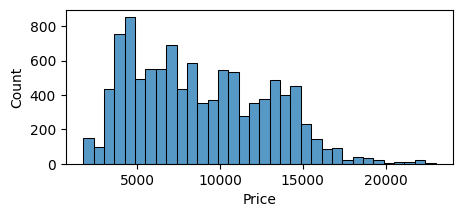

In [66]:
plt.figure(figsize=(5,2))
sns.histplot(data,x='Price')
plt.show()

In [67]:
data['Price']

0         3897
1         7662
2        13882
3         6218
4        13302
         ...  
10678     4107
10679     4145
10680     7229
10681    12648
10682    11753
Name: Price, Length: 10462, dtype: int64

In [68]:
df = data[['Price']]=np.log(data[['Price']])

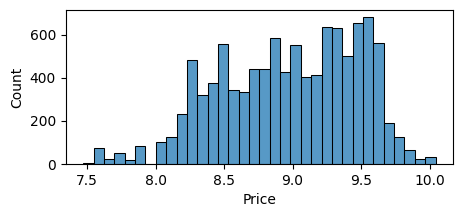

In [69]:
plt.figure(figsize=(5,2))
sns.histplot(df,x='Price')
plt.show()

In [70]:
data.select_dtypes(include="object")

""
0
1
2
3
4
...
10678
10679
10680
10681


In [71]:
# spliting of data
x= data.drop(columns=['Price','Dep_Time','Arrival_Time','Duration','Additional_Info','Date_of_Journey'])
y = data.loc[:,'Price']

In [72]:
x

,Airline,Source,Destination,Route,Total_Stops,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Period,Duration_Minutes,Dep_Time_Minutes,Arrival_Time_Minutes,Arrival_Date,Arrival_Month
0,3,0,5,18,4,24,3,2019,22,2,0.057793,0.932862,70,13,2
1,1,3,0,84,1,1,5,2019,5,1,0.154116,0.233216,795,19,4
2,4,2,1,118,1,9,6,2019,9,3,0.397548,0.385159,265,6,1
3,3,3,0,91,0,12,5,2019,18,2,0.112084,0.752650,1410,19,4
4,3,0,5,29,0,1,3,2019,16,0,0.098074,0.699647,1295,19,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,0,3,0,64,4,9,4,2019,19,2,0.050788,0.830389,1345,19,4
10679,1,3,0,64,4,27,4,2019,20,2,0.052539,0.865724,1400,19,4
10680,4,0,2,18,4,27,4,2019,8,3,0.061296,0.339223,680,19,4
10681,10,0,5,18,4,1,3,2019,11,3,0.054291,0.473498,850,19,4


In [73]:
y 

0        8.267962
1        8.944028
2        9.538348
3        8.735204
4        9.495670
           ...   
10678    8.320448
10679    8.329658
10680    8.885856
10681    9.445254
10682    9.371864
Name: Price, Length: 10462, dtype: float64

In [74]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [75]:
x_train

,Airline,Source,Destination,Route,Total_Stops,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Period,Duration_Minutes,Dep_Time_Minutes,Arrival_Time_Minutes,Arrival_Date,Arrival_Month
6727,3,4,3,48,4,1,5,2019,9,3,0.029772,0.374558,640,19,4
6322,4,2,1,104,0,9,5,2019,10,3,0.187391,0.409894,1140,19,4
6874,6,2,1,104,0,1,6,2019,10,3,0.323993,0.409894,90,0,1
3493,3,3,0,90,0,6,5,2019,8,3,0.099825,0.332155,780,19,4
611,1,2,1,104,0,21,3,2019,23,2,0.423818,0.961131,1155,13,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5799,3,0,2,18,4,3,6,2019,8,3,0.057793,0.346290,680,19,4
5247,4,0,5,5,0,21,3,2019,7,3,0.299475,0.282686,1280,19,4
5452,3,2,1,104,0,3,4,2019,10,3,0.103327,0.434629,935,19,4
861,3,2,1,106,4,27,4,2019,5,1,0.066550,0.222615,530,19,4


In [76]:
y_train

6727    8.428362
6322    9.652073
6874    9.501292
3493    8.530899
611     8.816557
          ...   
5799    8.481151
5247    8.965973
5452    8.531688
861     8.702012
7367    8.172729
Name: Price, Length: 8369, dtype: float64

In [77]:
x_test

,Airline,Source,Destination,Route,Total_Stops,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Period,Duration_Minutes,Dep_Time_Minutes,Arrival_Time_Minutes,Arrival_Date,Arrival_Month
2150,4,0,5,5,0,6,3,2019,8,3,0.507881,0.325088,495,4,2
3784,8,3,0,64,4,6,6,2019,22,2,0.047285,0.932862,40,4,1
714,3,3,0,64,4,18,3,2019,5,1,0.057793,0.219081,500,19,4
7558,4,4,3,48,4,24,3,2019,15,0,0.029772,0.657244,1040,19,4
7413,8,0,2,18,4,27,4,2019,9,3,0.057793,0.388693,740,19,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
653,4,2,1,104,0,27,5,2019,19,2,0.362522,0.802120,755,17,3
8607,4,2,1,104,0,27,5,2019,2,1,0.350263,0.081272,1140,19,4
10261,4,2,1,104,0,3,6,2019,2,1,0.548161,0.081272,265,2,1
10581,6,2,1,104,0,6,6,2019,15,0,0.213660,0.632509,90,4,1


In [78]:
data.shape

(10462, 21)

In [79]:
# import Linear Regression model
from sklearn.linear_model import LinearRegression
# initialise the model
model = LinearRegression()
# train the model :x_train,y_train
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [80]:
y_pred=model.predict(x_test)

In [81]:
model.coef_

array([ 7.57498916e-04, -7.06775330e-02, -2.26126672e-02,  2.92374538e-04,
       -1.40962934e-01, -6.72300297e-03, -2.13472845e-02, -6.66133815e-16,
        5.93516519e-02,  1.01280886e-03,  1.09647780e+00, -1.20623343e+00,
       -9.00847420e-05,  3.08556673e-03,  5.32020441e-02])

In [82]:
model.intercept_

np.float64(9.036169660500416)

In [83]:
# Evaluate the Model
# MSE
# MAE
# RMSE
# MAPE
# r2 score
# adjusted r2 score

In [84]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,mean_absolute_percentage_error,r2_score

In [85]:
mse=mean_squared_error(y_test,y_pred)
mse

0.10759793671800179

In [86]:
mae = mean_absolute_error(y_test,y_pred)
mae

0.26782835613175066

In [87]:
rmse = np.sqrt(mse)
rmse

np.float64(0.3280212443089651)

In [88]:
mape = mean_absolute_percentage_error(y_test,y_pred)
mape

0.03000554036607865

In [89]:
r2=r2_score(y_test,y_pred)
r2

0.5667152152341395

In [90]:
# adj = 1-(1-r2)(n-1)/(n-p-1)
n = x_test.shape[0]
n

2093

In [91]:
p = x_test.shape[1]
p

15

In [92]:
adj = 1 - (1-r2)*(n-1)/(n-p-1)
adj

0.5635860521279825

In [95]:
from sklearn.neighbors import KNeighborsRegressor
model = KNeighborsRegressor(n_neighbors=3)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [96]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.06103973011810917
MAE=0.1749396495958819
RMSE=0.24706219888544093
MAPE=0.01952537673173855
R2=0.7541998747085055


In [97]:
r2=r2_score(y_test,y_pred)
adj = 1 - (1-r2)*(n-1)/(n-p-1)
adj

0.7524247173279699

In [98]:
# decision tree
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor()
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [99]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.057776594436230067
MAE=0.1413016848836203
RMSE=0.24036762351912136
MAPE=0.015731849824731817
R2=0.7673401549472457


In [100]:
r2=r2_score(y_test,y_pred)
adj = 1 - (1-r2)*(n-1)/(n-p-1)
adj

0.765659896075897

In [101]:
# decision tree with hyper parameter
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor(criterion='squared_error',max_depth=6,max_features='sqrt',min_samples_split=5,min_samples_leaf=3)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [102]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.06930325256117421
MAE=0.2076922279547934
RMSE=0.2632551092783846
MAPE=0.023218721361983895
R2=0.7209235996017147


In [103]:
# decision tree with kfold
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
model = DecisionTreeRegressor(criterion='squared_error',max_depth=6,max_features='sqrt',min_samples_split=5,min_samples_leaf=3)
kfold = KFold(n_splits=5,shuffle=True,random_state=42)
scores = cross_val_score(model,x_train,y_train,cv=kfold)

In [104]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.06930325256117421
MAE=0.2076922279547934
RMSE=0.2632551092783846
MAPE=0.023218721361983895
R2=0.7209235996017147


In [105]:
r2=r2_score(y_test,y_pred)
adj = 1 - (1-r2)*(n-1)/(n-p-1)
adj

0.7189081224683617

In [106]:
# decision tree with stratified kfold
from sklearn.model_selection import StratifiedKFold
model = DecisionTreeRegressor(criterion='squared_error',max_depth=6,max_features='sqrt',min_samples_split=5,min_samples_leaf=3)
sfold = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scores = cross_val_score(model,x_train,y_train)

In [107]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.06930325256117421
MAE=0.2076922279547934
RMSE=0.2632551092783846
MAPE=0.023218721361983895
R2=0.7209235996017147


In [108]:
r2=r2_score(y_test,y_pred)
adj = 1 - (1-r2)*(n-1)/(n-p-1)
adj

0.7189081224683617

In [109]:
# random forest
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [110]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.03656416836099596
MAE=0.12351047056769522
RMSE=0.1912175942767714
MAPE=0.013746319877514922
R2=0.8527602080330018


In [111]:
r2=r2_score(y_test,y_pred)
adj = 1 - (1-r2)*(n-1)/(n-p-1)
adj

0.8516968489191332

In [112]:
# random forest with hyper parameter
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators=10,max_depth=6,max_features=5,bootstrap=True,min_samples_split=5,min_samples_leaf=3)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [113]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.05502568887319203
MAE=0.18800665598645433
RMSE=0.2345755504591048
MAPE=0.020995452874517415
R2=0.7784177421310595


In [114]:
r2=r2_score(y_test,y_pred)
adj = 1 - (1-r2)*(n-1)/(n-p-1)
adj

0.7768174850930074

In [115]:
# gradient booster
from sklearn.ensemble import GradientBoostingRegressor
model=GradientBoostingRegressor()
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [116]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.04436669295384659
MAE=0.16397150664876425
RMSE=0.21063402610653054
MAPE=0.018318357766712517
R2=0.8213403193997841


In [117]:
r2=r2_score(y_test,y_pred)
adj = 1 - (1-r2)*(n-1)/(n-p-1)
adj

0.8200500472721948

In [118]:
!pip install xgboost


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [119]:
from xgboost import XGBRegressor
model = XGBRegressor()
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [120]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.027785059035291458
MAE=0.11592359885207305
RMSE=0.1666885090079441
MAPE=0.012931823528110252
R2=0.8881126935048484


In [121]:
r2=r2_score(y_test,y_pred)
adj = 1 - (1-r2)*(n-1)/(n-p-1)
adj

0.8873046484410896

In [93]:
# Grid Search CV with gradient boosting
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
model = GradientBoostingRegressor()
parameters = {'max_depth':[5,6,7],'n_estimators':[100,200,300],
              'learning_rate':[0.01,0.1,0.2]}
grid = GridSearchCV(estimator=model,param_grid=parameters,cv=5 )
grid.fit(x_train,y_train)

,estimator,GradientBoostingRegressor()
,param_grid,"{'learning_rate': [0.01, 0.1, ...], 'max_depth': [5, 6, ...], 'n_estimators': [100, 200, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'squared_error'


In [94]:
print(grid.best_params_)

{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300}


In [95]:
# grid Search for Gradient Boosting with best parameters
model = GradientBoostingRegressor(learning_rate=0.1,max_depth= 5,n_estimators=300)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [96]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.02742575199130429
MAE=0.12091056073096401
RMSE=0.16560722203848566
MAPE=0.013487926765493463
R2=0.8895595825435003


In [126]:
# Randomised Search for Gradient Boosting
from sklearn.model_selection import RandomizedSearchCV
parameters = {'max_depth':[5,6,7],'n_estimators':[100,200,300],
              'learning_rate':[0.01,0.1,0.2]}
model = GradientBoostingRegressor()
random = RandomizedSearchCV(estimator=model,param_distributions=parameters,cv=5 , n_iter=10)
random.fit(x_train,y_train)

,estimator,GradientBoostingRegressor()
,param_distributions,"{'learning_rate': [0.01, 0.1, ...], 'max_depth': [5, 6, ...], 'n_estimators': [100, 200, ...]}"
,n_iter,10
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [127]:
print(random.best_params_)

{'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.1}


In [128]:
 # Randomised Search for Gradient Boosting with best parameters
model = GradientBoostingRegressor(n_estimators=300,max_depth=6,learning_rate=0.1)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [129]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.027757725478282303
MAE=0.11689691554753773
RMSE=0.1666064989077026
MAPE=0.013034547393571148
R2=0.8882227626634851


In [131]:
# XG booster 
from xgboost import XGBRegressor
model = XGBRegressor()
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [132]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.027785059035291458
MAE=0.11592359885207305
RMSE=0.1666885090079441
MAPE=0.012931823528110252
R2=0.8881126935048484


In [133]:
# XG booster with grid search 
from xgboost import XGBRegressor
model = XGBRegressor()
parameters = {'max_depth':[4,5,6],'n_estimators':[10,50,100,200,300],
              'learning_rate':[0.1,0.01,0.2],'reg_alpha':[0.1,0.01,0.2,0.3],
              'reg_lambda':[1,5,8,10]}
grid = GridSearchCV(estimator=model,param_grid=parameters,cv=5)
grid.fit(x_train,y_train)

,estimator,"XGBRegressor(...ree=None, ...)"
,param_grid,"{'learning_rate': [0.1, 0.01, ...], 'max_depth': [4, 5, ...], 'n_estimators': [10, 50, ...], 'reg_alpha': [0.1, 0.01, ...], ...}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'reg:squarederror'


In [ ]:
print(random.best_params_)

In [ ]:
model = XGRegressor(learning_rate=0.1,max_depth= 5,n_estimators=300)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [134]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.027785059035291458
MAE=0.11592359885207305
RMSE=0.1666885090079441
MAPE=0.012931823528110252
R2=0.8881126935048484


In [135]:
# XG booster with randomized search
model = XGBRegressor()
parameters = {'max_depth':[4,5,6],'n_estimators':[10,50,100,200,300],
              'learning_rate':[0.1,0.01,0.2],'reg_alpha':[0.1,0.01,0.2,0.3],
              'reg_lambda':[1,5,8,10]}
random=RandomizedSearchCV(estimator=model,param_distributions=parameters,cv=5,n_iter=30)
random.fit(x_train,y_train)

,estimator,"XGBRegressor(...ree=None, ...)"
,param_distributions,"{'learning_rate': [0.1, 0.01, ...], 'max_depth': [4, 5, ...], 'n_estimators': [10, 50, ...], 'reg_alpha': [0.1, 0.01, ...], ...}"
,n_iter,30
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [ ]:
print(random.best_params_)

In [ ]:
model = XGRegressor(learning_rate=0.1,max_depth= 5,n_estimators=300)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [136]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.027785059035291458
MAE=0.11592359885207305
RMSE=0.1666885090079441
MAPE=0.012931823528110252
R2=0.8881126935048484


In [137]:
# support vector machine
from sklearn.svm import SVR
model = SVR()
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [138]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

MSE=0.21093781929522024
MAE=0.37556683918324774
RMSE=0.45927967437632183
MAPE=0.04256742353270905
R2=0.1505771353976313


In [ ]:
# support vector machine with grid search
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
model = SVR()
parameters ={'kernel':['linear','poly','rbf','sigmoid'],'C':[1,5,10,15],'gamma':[0.1,0.01,0.001]}
grid = GridSearchCV(estimator=model,param_grid=parameters,cv=5,scoring='r2')
grid.fit(x_train,y_train)

In [ ]:
print(random.best_params_)

In [ ]:
model = SVR(learning_rate=0.1,max_depth= 5,n_estimators=300)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [ ]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

In [ ]:
# support vector machine with randomized search
model = SVR()
parameters ={'kernel':['linear','poly','rbf','sigmoid'],'C':[1,5,10,15],'gamma':[0.1,0.01,0.001]}
random = RandomizedSearchCV(estimator=model,param_distributions=parameters,cv=5,n_iter=10,scoring='r2')
random.fit(x_train,y_train)

In [ ]:
print(random.best_params_)

In [ ]:
model = SVR(learning_rate=0.1,max_depth= 5,n_estimators=300)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [ ]:
print(f'MSE={mean_squared_error(y_test,y_pred)}\n'
      f'MAE={mean_absolute_error(y_test,y_pred)}\n'
      f'RMSE={np.sqrt(mean_squared_error(y_test,y_pred))}\n'
      f'MAPE={mean_absolute_percentage_error(y_test,y_pred)}\n'
      f'R2={r2_score(y_test,y_pred)}')

In [97]:
# pickle model to save the model file
import pickle

# Save the trained model to a .pkl file
filename = 'gradient_boosting.pkl'
pickle.dump(model, open(filename, 'wb'))

print(f"Model saved successfully as {filename}")

Model saved successfully as gradient_boosting.pkl
